In [1]:
import site
site.addsitedir("/home/jovyan/vault/heidelberg_lulc_2025/pylibs/lib/python3.11/site-packages")

import os, json
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle

PROJ = "/home/jovyan/vault/heidelberg_lulc_2025"
OUTA = f"{PROJ}/outputs/aligned"
SPLIT_DIR = f"{PROJ}/outputs/splits"
os.makedirs(SPLIT_DIR, exist_ok=True)
common = json.load(open(f"{PROJ}/outputs/alignment/common_grid.json"))

CLASS_NAMES = ["Water", "Trees", "Grass", "Flooded vegetation", "Crops",
               "Shrub and scrub", "Built-up", "Bare ground", "Snow and ice"]
PALETTE = ["#419bdf", "#397d49", "#88b053", "#7a87c6", "#e49635",
           "#dfc35a", "#c4281b", "#a59b8f", "#b39fe1"]

BLOCK10, BLOCK40, SB = 256, 64, 3          # block size (px), super-block = 3x3 blocks
H10, W10 = common["10m"]["height"], common["10m"]["width"]
nby, nbx = H10 // BLOCK10, W10 // BLOCK10
row0 = ((H10 - nby * BLOCK10) // 2) // 4 * 4    # centre the block grid, keep 40 m alignment
col0 = ((W10 - nbx * BLOCK10) // 2) // 4 * 4
print(f"Block grid: {nby} x {nbx} blocks of {BLOCK10*10/1000:.2f} km, offset row {row0}, col {col0} (10 m px)")

# --- class pixel counts per block, summed over all 12 months (10 m labels) ---
counts = np.zeros((nby, nbx, 9), dtype=np.int64)
for m in range(1, 13):
    with rasterio.open(f"{OUTA}/10m/DW_2025_{m:02d}_10m_lulc.tif") as src:
        lab = src.read(1)[row0:row0 + nby * BLOCK10, col0:col0 + nbx * BLOCK10]
    b = lab.reshape(nby, BLOCK10, nbx, BLOCK10).transpose(0, 2, 1, 3).reshape(nby, nbx, -1)
    for c in range(9):
        counts[:, :, c] += (b == c).sum(-1)
    print(f"  counted month {m:02d}")

# --- super-blocks ---
sb_y, sb_x = nby // SB, nbx // SB
sb_id = (np.arange(nby)[:, None] // SB) * sb_x + (np.arange(nbx)[None, :] // SB)
n_sb = sb_y * sb_x
sb_counts = np.stack([counts[sb_id == s].sum(0) for s in range(n_sb)])
total = sb_counts.sum(0)
p_total = total / total.sum()

# --- search for a balanced assignment ---
N_TEST, N_VAL = 4, 4
rng = np.random.default_rng(42)
best = None
for _ in range(20000):
    perm = rng.permutation(n_sb)
    parts = {"test": perm[:N_TEST], "val": perm[N_TEST:N_TEST + N_VAL], "train": perm[N_TEST + N_VAL:]}
    score = 0.0
    for idx in parts.values():
        c = sb_counts[idx].sum(0)
        expected = total * len(idx) / n_sb
        score += np.abs(c / c.sum() - p_total).sum()
        score += 2 * np.clip(0.5 - c[:8] / np.maximum(expected[:8], 1), 0, None).sum()  # rare-class penalty
    if best is None or score < best[0]:
        best = (score, parts)
score, parts = best
sb_split = np.empty(n_sb, dtype=object)
for name, idx in parts.items():
    sb_split[idx] = name

# --- block table ---
rows = []
for by in range(nby):
    for bx in range(nbx):
        r10, c10 = row0 + by * BLOCK10, col0 + bx * BLOCK10
        rows.append({"block_id": by * nbx + bx, "by": by, "bx": bx, "superblock": int(sb_id[by, bx]),
                     "split": sb_split[sb_id[by, bx]],
                     "row10": r10, "col10": c10, "row40": r10 // 4, "col40": c10 // 4,
                     **{f"n_{c}": int(counts[by, bx, c]) for c in range(9)}})
blocks = pd.DataFrame(rows)
blocks.to_csv(f"{SPLIT_DIR}/blocks_and_splits.csv", index=False)
json.dump({"block10": BLOCK10, "block40": BLOCK40, "superblock": SB, "row0_10m": row0, "col0_10m": col0,
           "nby": nby, "nbx": nbx, "seed": 42, "score": float(score),
           "superblock_split": {int(i): s for i, s in enumerate(sb_split)}},
          open(f"{SPLIT_DIR}/split_config.json", "w"), indent=2)

# --- summary table ---
summ = blocks.groupby("split")[[f"n_{c}" for c in range(9)]].sum()
pct = (100 * summ.div(summ.sum(1), axis=0)).round(2)
pct.columns = CLASS_NAMES
pct.loc["ALL"] = (100 * p_total).round(2)
print(f"\nBest score: {score:.4f}")
print(blocks.groupby("split").agg(blocks=("block_id", "count"), superblocks=("superblock", "nunique")))
print("\nClass share per split (% of labelled pixels, all 12 months):")
print(pct.to_string())

Block grid: 15 x 15 blocks of 2.56 km, offset row 80, col 72 (10 m px)
  counted month 01
  counted month 02
  counted month 03
  counted month 04
  counted month 05
  counted month 06
  counted month 07
  counted month 08
  counted month 09
  counted month 10
  counted month 11
  counted month 12

Best score: 0.0949
       blocks  superblocks
split                     
test       36            4
train     153           17
val        36            4

Class share per split (% of labelled pixels, all 12 months):
       Water  Trees  Grass  Flooded vegetation  Crops  Shrub and scrub  Built-up  Bare ground  Snow and ice
split                                                                                                      
test    3.24  41.33   6.26                0.01  22.54             1.79     23.34         0.41          1.08
train   3.24  42.25   6.23                0.03  21.93             1.75     23.66         0.33          0.57
val     4.59  41.21   4.68                0.01  23.8

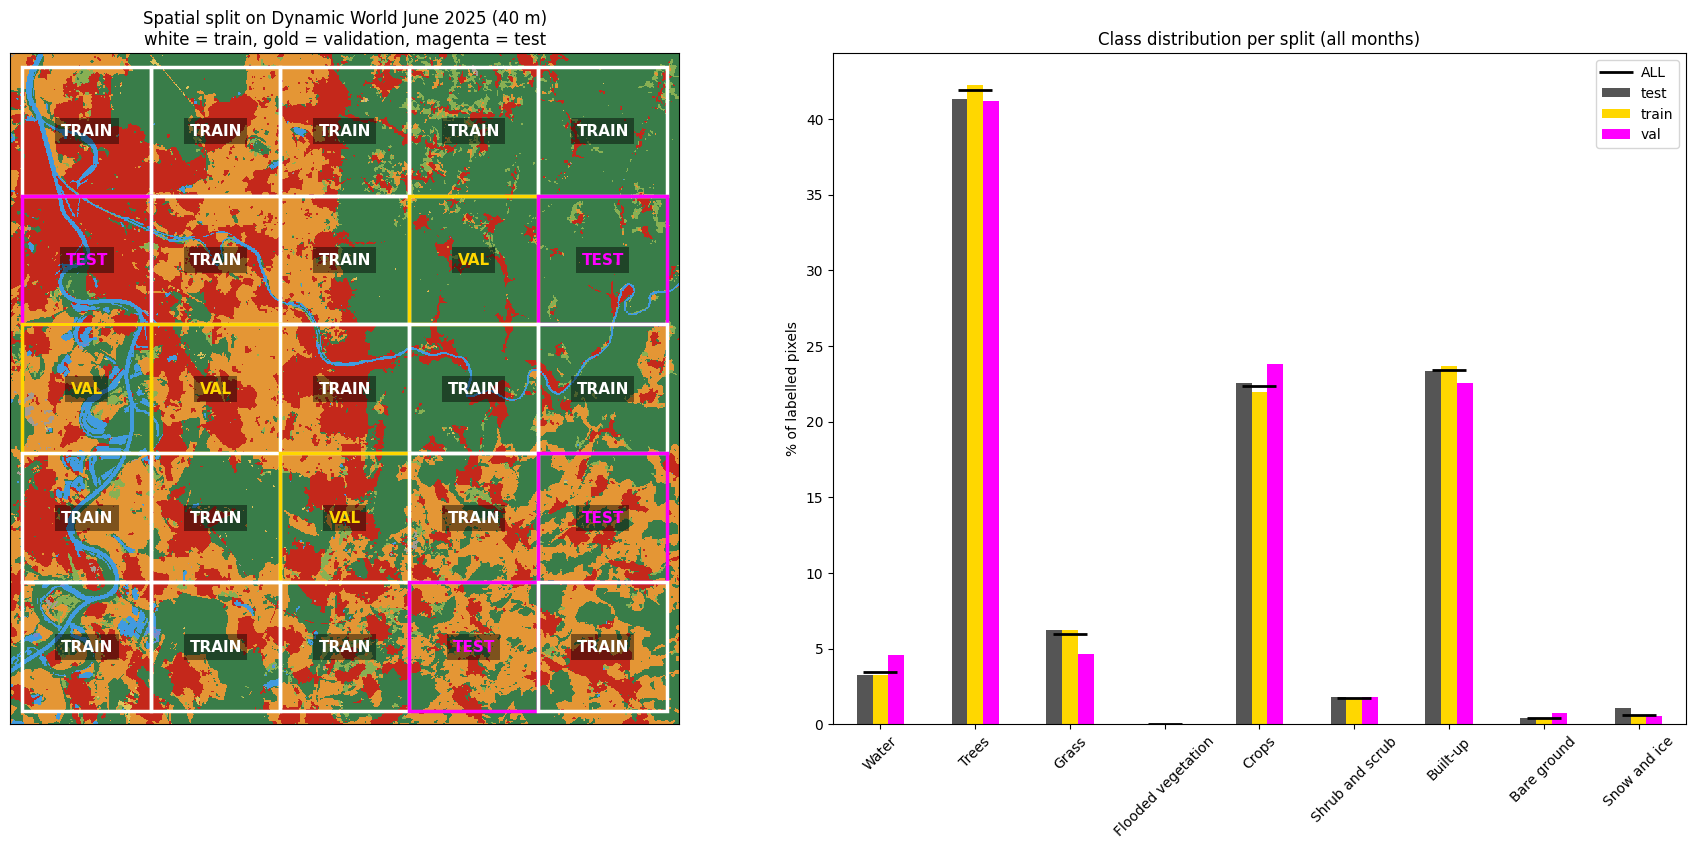

Saved: /home/jovyan/vault/heidelberg_lulc_2025/outputs/splits/split_map_and_distribution.png


In [2]:
with rasterio.open(f"{OUTA}/40m/DW_2025_06_40m_lulc.tif") as src:
    lab40 = src.read(1).astype(float)
lab40[lab40 == 255] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
cmap = ListedColormap(PALETTE)
norm = BoundaryNorm(np.arange(-0.5, 9.5, 1), cmap.N)
colors = {"train": "white", "val": "gold", "test": "magenta"}

ax = axes[0]
ax.imshow(lab40, cmap=cmap, norm=norm, interpolation="nearest")
r0, c0 = row0 // 4, col0 // 4
for s in range(n_sb):
    ys, xs = np.where(sb_id == s)
    y, x = r0 + ys.min() * BLOCK40, c0 + xs.min() * BLOCK40
    size = SB * BLOCK40
    ax.add_patch(Rectangle((x, y), size, size, fill=False, lw=2.5, ec=colors[sb_split[s]]))
    ax.text(x + size / 2, y + size / 2, sb_split[s].upper(), color=colors[sb_split[s]],
            ha="center", va="center", fontsize=11, weight="bold",
            bbox=dict(fc="black", alpha=0.45, lw=0))
ax.set_title("Spatial split on Dynamic World June 2025 (40 m)\nwhite = train, gold = validation, magenta = test")
ax.set_xticks([]); ax.set_yticks([])

ax = axes[1]
pct.drop(index="ALL").T.plot.bar(ax=ax, color=["#555555", "gold", "magenta"][:len(pct) - 1])
ax.plot(range(9), pct.loc["ALL"].values, "k_", ms=25, mew=2, label="ALL")
ax.set_ylabel("% of labelled pixels"); ax.set_title("Class distribution per split (all months)")
ax.legend(); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(f"{SPLIT_DIR}/split_map_and_distribution.png", dpi=150)
plt.show()
print("Saved:", f"{SPLIT_DIR}/split_map_and_distribution.png")

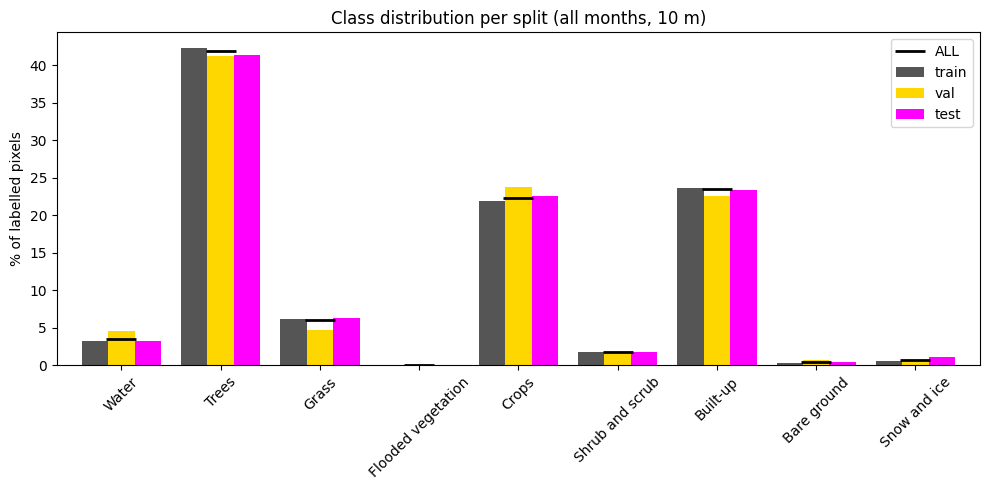

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
order = ["train", "val", "test"]
pct.loc[order].T.plot.bar(ax=ax, color=["#555555", "gold", "magenta"], width=0.8)
ax.plot(range(9), pct.loc["ALL"].values, "k_", ms=22, mew=2, label="ALL")
ax.set_ylabel("% of labelled pixels"); ax.set_title("Class distribution per split (all months, 10 m)")
ax.legend(); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(f"{SPLIT_DIR}/class_distribution_per_split.png", dpi=150); plt.show()

In [4]:
from numpy.lib.format import open_memmap

PATCH_DIR = f"{PROJ}/patches"
MIN_VALID = {"train": 0.25, "val": 0.05, "test": 0.05}
S1_NAMES = ["VV", "VH", "mean_n_obs"]

def read_all(path):
    with rasterio.open(path) as src:
        return src.read().astype(np.float32) if src.count > 1 else src.read(1)

for res in (10, 40):
    size = BLOCK10 if res == 10 else BLOCK40
    rk, ck = ("row10", "col10") if res == 10 else ("row40", "col40")
    out = f"{PATCH_DIR}/{res}m"
    os.makedirs(out, exist_ok=True)

    # ---- pass 1: decide which (month, block) patches to keep ----
    keep = []
    for m in range(1, 13):
        lab = read_all(f"{OUTA}/{res}m/DW_2025_{m:02d}_{res}m_lulc.tif")
        for r in blocks.itertuples():
            y = lab[getattr(r, rk):getattr(r, rk) + size, getattr(r, ck):getattr(r, ck) + size]
            frac = float((y != 255).mean())
            if frac >= MIN_VALID[r.split]:
                keep.append((r.split, m, r.block_id, r.by, r.bx, r.superblock,
                             getattr(r, rk), getattr(r, ck), round(frac, 4)))
    meta = pd.DataFrame(keep, columns=["split", "month", "block_id", "by", "bx", "superblock",
                                       "row", "col", "valid_frac"])
    meta = meta.sort_values(["split", "month", "block_id"]).reset_index(drop=True)
    meta["idx"] = meta.groupby("split").cumcount()

    with rasterio.open(f"{OUTA}/{res}m/DW_2025_01_{res}m_aux.tif") as src:
        aux_names = list(src.descriptions)

    # ---- allocate files on disk ----
    arrays = {}
    for split, g in meta.groupby("split"):
        n = len(g)
        arrays[split] = {
            "X":   open_memmap(f"{out}/{split}_X.npy",   mode="w+", dtype=np.float32, shape=(n, 3, size, size)),
            "Y":   open_memmap(f"{out}/{split}_Y.npy",   mode="w+", dtype=np.uint8,   shape=(n, size, size)),
            "AUX": open_memmap(f"{out}/{split}_AUX.npy", mode="w+", dtype=np.float32, shape=(n, len(aux_names), size, size)),
        }
        g.drop(columns="idx").assign(patch_index=g["idx"].values).to_csv(f"{out}/{split}_meta.csv", index=False)

    # ---- pass 2: fill them, one month at a time ----
    for m in range(1, 13):
        s1  = read_all(f"{OUTA}/{res}m/S1_2025_{m:02d}_{res}m.tif")
        lab = read_all(f"{OUTA}/{res}m/DW_2025_{m:02d}_{res}m_lulc.tif")
        aux = read_all(f"{OUTA}/{res}m/DW_2025_{m:02d}_{res}m_aux.tif")
        if aux.ndim == 2:
            aux = aux[None]
        for r in meta[meta.month == m].itertuples():
            ys, xs = slice(r.row, r.row + size), slice(r.col, r.col + size)
            a = arrays[r.split]
            a["X"][r.idx]   = s1[:, ys, xs]
            a["Y"][r.idx]   = lab[ys, xs]
            a["AUX"][r.idx] = aux[:, ys, xs]
        print(f"{res} m: month {m:02d} written ({(meta.month == m).sum()} patches)")
        del s1, lab, aux

    for a in arrays.values():
        for arr in a.values():
            arr.flush()
    del arrays

    json.dump({"resolution_m": res, "patch_size": size, "inputs": S1_NAMES, "aux": aux_names,
               "label_nodata": 255, "min_valid": MIN_VALID, "class_names": CLASS_NAMES},
              open(f"{out}/dataset_info.json", "w"), indent=2)
    print(f"\n{res} m done:", meta.groupby("split").size().to_dict(), "\n")

10 m: month 01 written (133 patches)
10 m: month 02 written (225 patches)
10 m: month 03 written (225 patches)
10 m: month 04 written (225 patches)
10 m: month 05 written (225 patches)
10 m: month 06 written (225 patches)
10 m: month 07 written (225 patches)
10 m: month 08 written (225 patches)
10 m: month 09 written (225 patches)
10 m: month 10 written (215 patches)
10 m: month 11 written (100 patches)
10 m: month 12 written (225 patches)

10 m done: {'test': 404, 'train': 1670, 'val': 399} 

40 m: month 01 written (134 patches)
40 m: month 02 written (225 patches)
40 m: month 03 written (225 patches)
40 m: month 04 written (225 patches)
40 m: month 05 written (225 patches)
40 m: month 06 written (225 patches)
40 m: month 07 written (225 patches)
40 m: month 08 written (225 patches)
40 m: month 09 written (225 patches)
40 m: month 10 written (216 patches)
40 m: month 11 written (100 patches)
40 m: month 12 written (225 patches)

40 m done: {'test': 404, 'train': 1672, 'val': 399} 




==================== 10 m ====================
train:  1670 patches | X (3, 256, 256) | NaN in inputs: 0 | labels outside 0-8/255: 0 | labelled 96.8 % | months [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
val  :   399 patches | X (3, 256, 256) | NaN in inputs: 0 | labels outside 0-8/255: 0 | labelled 96.2 % | months [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
test :   404 patches | X (3, 256, 256) | NaN in inputs: 0 | labels outside 0-8/255: 0 | labelled 95.4 % | months [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
normalization (train only): {'VV': {'clip_low': -20.938, 'clip_high': 4.913, 'mean': -9.303, 'std': 3.62}, 'VH': {'clip_low': -27.762

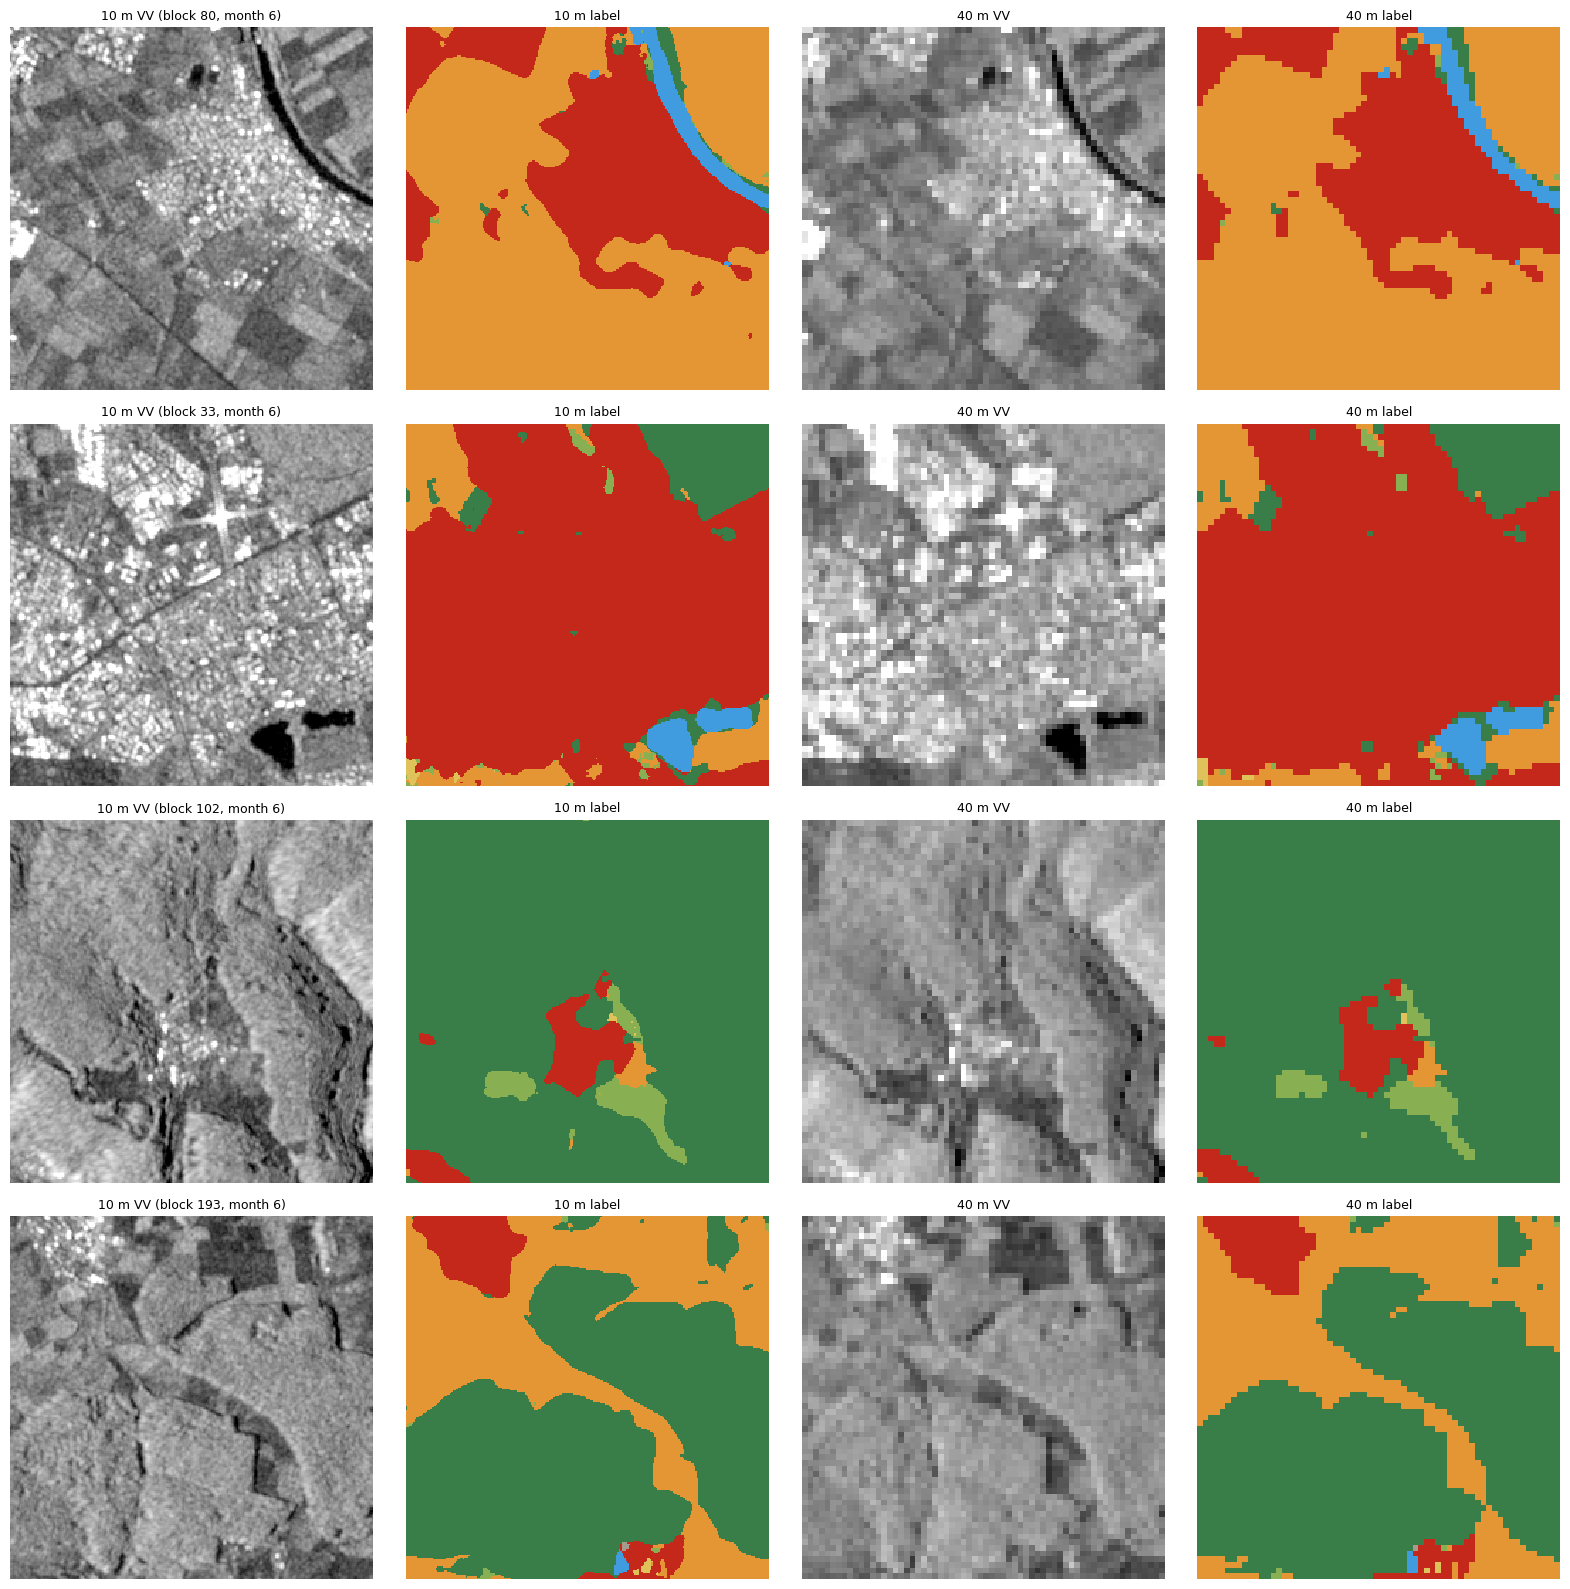

In [5]:
summary = []
for res in (10, 40):
    out = f"{PATCH_DIR}/{res}m"
    print(f"\n==================== {res} m ====================")
    for split in ("train", "val", "test"):
        X = np.load(f"{out}/{split}_X.npy", mmap_mode="r")
        Y = np.load(f"{out}/{split}_Y.npy", mmap_mode="r")
        meta = pd.read_csv(f"{out}/{split}_meta.csv")

        n_nan = 0
        cls = np.zeros(256, dtype=np.int64)
        for i in range(0, len(X), 64):                       # chunked: low memory
            n_nan += int(np.isnan(X[i:i+64]).sum())
            cls += np.bincount(np.asarray(Y[i:i+64]).ravel(), minlength=256)
        bad = int(cls[9:255].sum())
        labelled = cls[:9].sum()
        pct = 100 * cls[:9] / labelled
        print(f"{split:5s}: {len(X):5d} patches | X {X.shape[1:]} | NaN in inputs: {n_nan} | "
              f"labels outside 0-8/255: {bad} | labelled {100*labelled/cls.sum():.1f} % | "
              f"months {sorted(meta.month.unique())}")
        summary.append({"res_m": res, "split": split, "patches": len(X), "nan_inputs": n_nan,
                        "bad_labels": bad, **{CLASS_NAMES[c]: round(pct[c], 3) for c in range(9)}})

    # ---- normalization statistics from TRAIN only ----
    X = np.load(f"{out}/train_X.npy", mmap_mode="r")
    sample = np.asarray(X[np.random.default_rng(0).choice(len(X), min(300, len(X)), replace=False)])
    stats = {}
    for c, name in enumerate(["VV", "VH", "mean_n_obs"]):
        v = sample[:, c].ravel()
        v = v[np.isfinite(v)]
        lo, hi = np.percentile(v, [0.5, 99.5])
        vc = np.clip(v, lo, hi)
        stats[name] = {"clip_low": float(lo), "clip_high": float(hi),
                       "mean": float(vc.mean()), "std": float(vc.std())}
    json.dump(stats, open(f"{out}/norm_stats_train.json", "w"), indent=2)
    print("normalization (train only):",
          {k: {kk: round(vv, 3) for kk, vv in s.items()} for k, s in stats.items()})

summ = pd.DataFrame(summary)
summ.to_csv(f"{PATCH_DIR}/patch_summary.csv", index=False)
print("\nClass share (% of labelled pixels) per resolution and split:")
print(summ.set_index(["res_m", "split"])[CLASS_NAMES].round(2).to_string())

# ---- visual check: the same 4 train patches at 10 m and 40 m ----
m10 = pd.read_csv(f"{PATCH_DIR}/10m/train_meta.csv")
m40 = pd.read_csv(f"{PATCH_DIR}/40m/train_meta.csv").set_index(["month", "block_id"])
X10 = np.load(f"{PATCH_DIR}/10m/train_X.npy", mmap_mode="r"); Y10 = np.load(f"{PATCH_DIR}/10m/train_Y.npy", mmap_mode="r")
X40 = np.load(f"{PATCH_DIR}/40m/train_X.npy", mmap_mode="r"); Y40 = np.load(f"{PATCH_DIR}/40m/train_Y.npy", mmap_mode="r")
picks = m10[(m10.month == 6) & m10.set_index(["month", "block_id"]).index.isin(m40.index)].sample(4, random_state=1)

fig, axs = plt.subplots(4, 4, figsize=(16, 16))
for row, r in enumerate(picks.itertuples()):
    j = int(m40.loc[(r.month, r.block_id), "patch_index"])
    for col, (img, title, kw) in enumerate([
            (X10[r.patch_index, 0], f"10 m VV (block {r.block_id}, month {r.month})", dict(cmap="gray", vmin=-20, vmax=0)),
            (Y10[r.patch_index], "10 m label", dict(cmap=cmap, norm=norm)),
            (X40[j, 0], "40 m VV", dict(cmap="gray", vmin=-20, vmax=0)),
            (Y40[j], "40 m label", dict(cmap=cmap, norm=norm))]):
        show = img.astype(float)
        if "label" in title:
            show[show == 255] = np.nan
        axs[row, col].imshow(show, interpolation="nearest", **kw)
        axs[row, col].set_title(title, fontsize=9); axs[row, col].axis("off")
plt.tight_layout(); plt.savefig(f"{PATCH_DIR}/patch_examples.png", dpi=120); plt.show()